In [1]:

# Step 1: Import Libraries

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile

from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:

!pip install -q kagglehub


In [3]:

import kagglehub

# Download dataset
path = kagglehub.dataset_download(
    "puneet6060/intel-image-classification"
)

print("Dataset downloaded successfully!")
print("Dataset location:", path)

# Display folder contents
print("\nDataset folders:")

for folder in os.listdir(path):
    print(folder)


Using Colab cache for faster access to the 'intel-image-classification' dataset.
Dataset downloaded successfully!
Dataset location: /kaggle/input/intel-image-classification

Dataset folders:
seg_train
seg_pred
seg_test


In [4]:

# Step 4: Inspect Dataset Structure

print("Dataset Path:", path)

for root, dirs, files in os.walk(path):
    level = root.replace(path, '').count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        if level == 2:
            print("  " * (level + 1),
                  "Number of images:", len(files))


Dataset Path: /kaggle/input/intel-image-classification
intel-image-classification/
  seg_train/
    seg_train/
       Number of images: 0
  seg_pred/
    seg_pred/
       Number of images: 7301
  seg_test/
    seg_test/
       Number of images: 0


In [5]:

# Inspect nested folders

for root, dirs, files in os.walk(path):
    print("\nFolder:", root)
    print("Subfolders:", dirs)
    print("Number of files:", len(files))

    if root.count(os.sep) - path.count(os.sep) >= 4:
        dirs[:] = []



Folder: /kaggle/input/intel-image-classification
Subfolders: ['seg_train', 'seg_pred', 'seg_test']
Number of files: 0

Folder: /kaggle/input/intel-image-classification/seg_train
Subfolders: ['seg_train']
Number of files: 0

Folder: /kaggle/input/intel-image-classification/seg_train/seg_train
Subfolders: ['mountain', 'street', 'buildings', 'sea', 'forest', 'glacier']
Number of files: 0

Folder: /kaggle/input/intel-image-classification/seg_train/seg_train/mountain
Subfolders: []
Number of files: 2512

Folder: /kaggle/input/intel-image-classification/seg_train/seg_train/street
Subfolders: []
Number of files: 2382

Folder: /kaggle/input/intel-image-classification/seg_train/seg_train/buildings
Subfolders: []
Number of files: 2191

Folder: /kaggle/input/intel-image-classification/seg_train/seg_train/sea
Subfolders: []
Number of files: 2274

Folder: /kaggle/input/intel-image-classification/seg_train/seg_train/forest
Subfolders: []
Number of files: 2271

Folder: /kaggle/input/intel-image-clas

In [7]:

import os

path = "/kaggle/input/intel-image-classification"

train_dir = os.path.join(path, "seg_train", "seg_train")
test_dir = os.path.join(path, "seg_test", "seg_test")

print("Training directory exists:", os.path.exists(train_dir))
print("Testing directory exists:", os.path.exists(test_dir))


Training directory exists: True
Testing directory exists: True


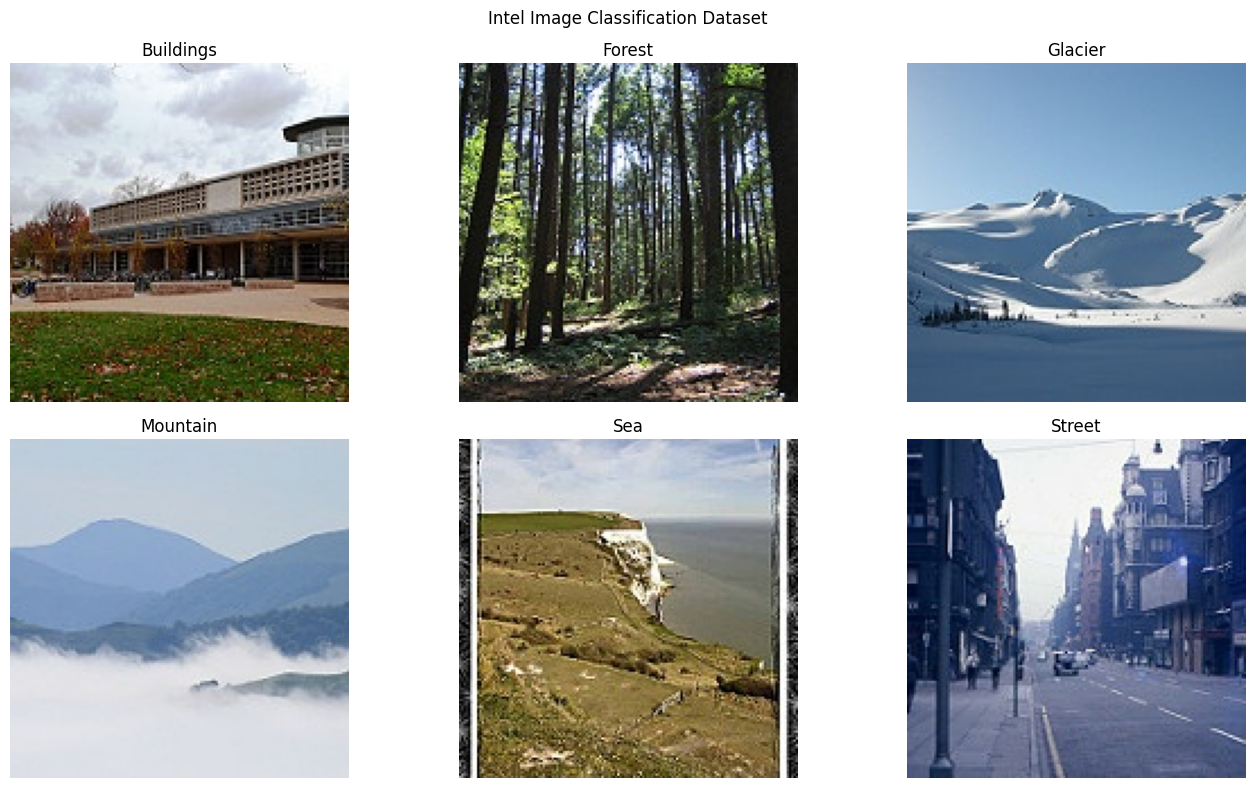

In [8]:

# Visualize Dataset Samples

import matplotlib.pyplot as plt
import tensorflow as tf

class_names = sorted(os.listdir(train_dir))

plt.figure(figsize=(14, 8))

for i, class_name in enumerate(class_names):

    folder = os.path.join(train_dir, class_name)

    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    image_path = os.path.join(folder, image_files[0])

    img = tf.keras.utils.load_img(image_path)

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(class_name.capitalize())
    plt.axis('off')

plt.suptitle("Intel Image Classification Dataset")
plt.tight_layout()
plt.show()


In [9]:

# Step 6: Load and Split Dataset

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Training dataset (80%)
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

# Validation dataset (20%)
val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

# Independent testing dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

class_names = train_ds.class_names

print("\nClasses:", class_names)
print("Number of classes:", len(class_names))


Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.

Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Number of classes: 6


In [10]:

# Step 7: Optimize Dataset Pipeline

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("Training pipeline ready!")
print("Validation pipeline ready!")
print("Testing pipeline ready!")

# Check one batch
for images, labels in train_ds.take(1):
    print("\nImage batch shape:", images.shape)
    print("Label batch shape:", labels.shape)


Training pipeline ready!
Validation pipeline ready!
Testing pipeline ready!

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32, 6)


In [11]:

# Step 8: Count samples in each split

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())


Training batches: 351
Validation batches: 88
Testing batches: 94


In [12]:

# Step 9.1: VGG16 Image Preprocessing

train_ds_vgg = train_ds.map(
    lambda images, labels: (preprocess_input(images), labels)
)

val_ds_vgg = val_ds.map(
    lambda images, labels: (preprocess_input(images), labels)
)

test_ds_vgg = test_ds.map(
    lambda images, labels: (preprocess_input(images), labels)
)

print("VGG16 preprocessing completed!")


VGG16 preprocessing completed!


In [13]:

# Step 9.2: Load VGG16 Base Model

vgg_base = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained convolutional layers
vgg_base.trainable = False

print("VGG16 loaded successfully!")
print("Pretrained weights: ImageNet")
print("Convolutional base frozen:", not vgg_base.trainable)


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
VGG16 loaded successfully!
Pretrained weights: ImageNet
Convolutional base frozen: True


In [14]:

# Step 9.3: Build VGG16 Classification Model

model = models.Sequential([
    vgg_base,

    layers.GlobalAveragePooling2D(),

    layers.Dense(256, activation='relu'),

    layers.Dropout(0.5),

    layers.Dense(6, activation='softmax')
])

print("VGG16 Classification Model Created!")


VGG16 Classification Model Created!


In [15]:

# Step 9.4: Model Summary

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,847,558 (56.64 MB)

 Trainable params: 132,870 (519.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [16]:

# Step 10: Training Callbacks

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    'vgg16_baseline_best.keras',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max'
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.000001
)

callbacks = [
    early_stop,
    checkpoint,
    reduce_lr
]

print("Training callbacks configured!")


Training callbacks configured!


In [18]:

# Recompile VGG16 Model

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")


Model compiled successfully!


In [19]:

print("Model:", model.name)
print("Optimizer:", model.optimizer)
print("Loss:", model.loss)
print("Trainable parameters:", sum(
    np.prod(v.shape) for v in model.trainable_variables
))


Model: sequential
Optimizer: <keras.src.optimizers.adam.Adam object at 0x784646b17380>
Loss: categorical_crossentropy
Trainable parameters: 132870


In [20]:

EPOCHS = 10

history = model.fit(
    train_ds_vgg,
    validation_data=val_ds_vgg,
    epochs=EPOCHS,
    callbacks=callbacks
)


Epoch 1/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 126s 297ms/step - accuracy: 0.6547 - loss: 1.5829 - val_accuracy: 0.8845 - val_loss: 0.3732 - learning_rate: 1.0000e-04
Epoch 2/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 71s 203ms/step - accuracy: 0.8319 - loss: 0.5843 - val_accuracy: 0.8995 - val_loss: 0.3114 - learning_rate: 1.0000e-04
Epoch 3/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 72s 203ms/step - accuracy: 0.8639 - loss: 0.4478 - val_accuracy: 0.9038 - val_loss: 0.2851 - learning_rate: 1.0000e-04
Epoch 4/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 71s 202ms/step - accuracy: 0.8743 - loss: 0.3859 - val_accuracy: 0.9081 - val_loss: 0.2698 - learning_rate: 1.0000e-04
Epoch 5/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 71s 203ms/step - accuracy: 0.8882 - loss: 0.3356 - val_accuracy: 0.9163 - val_loss: 0.2550 - learning_rate: 1.0000e-04
Epoch 6/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 78s 221ms/step - accuracy: 0.8911 - loss: 0.3053 - val_accuracy: 0.9177 - val_loss: 0.2479 - learning_rate: 1.0000e-04
Epoch 7/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 71s 2

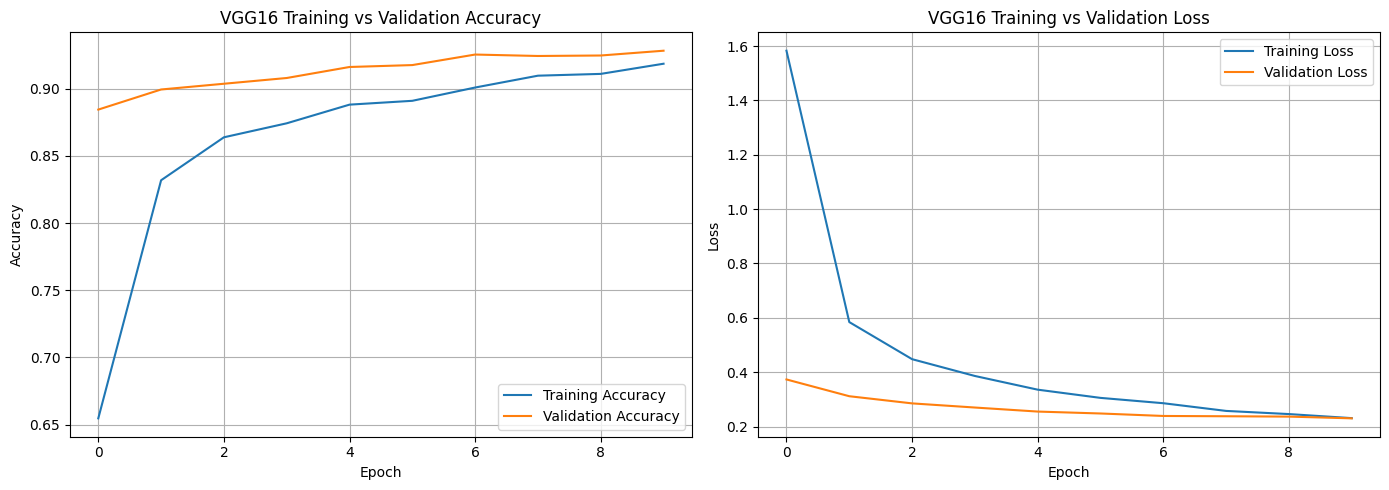

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('VGG16 Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('VGG16 Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [22]:
test_loss, test_accuracy = model.evaluate(test_ds_vgg)

print("Test Accuracy:", test_accuracy * 100, "%")
print("Test Loss:", test_loss)

94/94 ━━━━━━━━━━━━━━━━━━━━ 32s 334ms/step - accuracy: 0.9127 - loss: 0.2480
Test Accuracy: 91.26666784286499 %
Test Loss: 0.24800986051559448


94/94 ━━━━━━━━━━━━━━━━━━━━ 21s 178ms/step
              precision    recall  f1-score   support

   buildings       0.92      0.90      0.91       437
      forest       0.98      1.00      0.99       474
     glacier       0.85      0.84      0.85       553
    mountain       0.87      0.84      0.86       525
         sea       0.94      0.97      0.96       510
      street       0.92      0.93      0.92       501

    accuracy                           0.91      3000
   macro avg       0.91      0.91      0.91      3000
weighted avg       0.91      0.91      0.91      3000



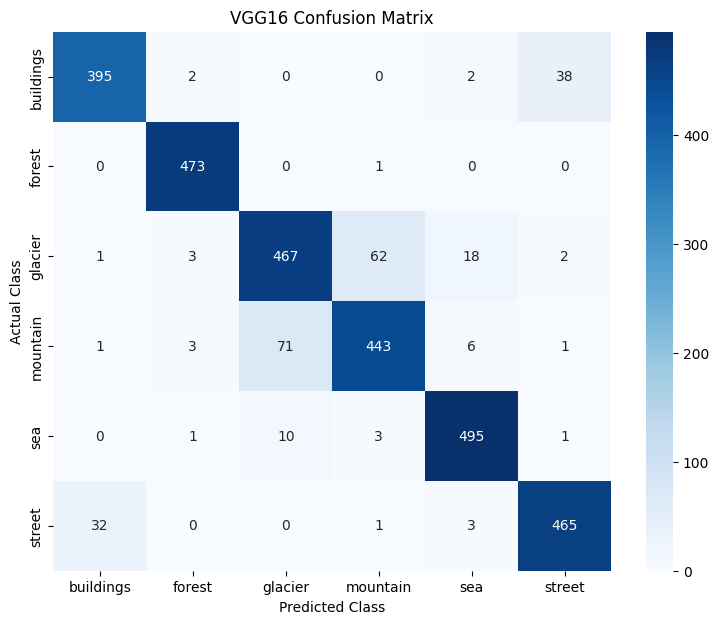

In [23]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Get predictions
y_pred = model.predict(test_ds_vgg)

# Convert probabilities and one-hot labels into class indices
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.concatenate([
    np.argmax(labels.numpy(), axis=1)
    for images, labels in test_ds_vgg
])

# Classification report
print(classification_report(
    y_true,
    y_pred_classes,
    target_names=class_names
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred_classes)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title('VGG16 Confusion Matrix')
plt.show()